# Figure 4 of Pucha et al. (2026)

In [1]:
import numpy as np

from astropy.table import Table, join, vstack

import sys
sys.path.append('/global/cfs/cdirs/desi/users/raga19/repos/DESI_Project/py/')

import bpt
import utils

import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm

from glob import glob

In [2]:
## Making the matplotlib plots look nicer
settings = {
    'mathtext.fontset': 'stix',
    'font.family': 'STIXGeneral',
    'font.size':22,
    'axes.labelsize': 'large',
    'lines.markersize': 5,
    'axes.linewidth':2.0,
    'xtick.major.size':6.0,
    'xtick.minor.size':4.0,
    'xtick.major.width':2.5,
    'xtick.minor.width':1.5,
    'xtick.direction':'in', 
    'xtick.minor.visible':True,
    'xtick.top':True,
    'ytick.major.size':6.0,
    'ytick.minor.size':4.0,
    'ytick.major.width':2.5,
    'ytick.minor.width':1.5,
    'ytick.direction':'in', 
    'ytick.minor.visible':True,
    'ytick.right':True,
    'contour.linewidth':3.0,
    'savefig.bbox': 'tight',
    'savefig.dpi': 200,
}

plt.rcParams.update(**settings)

In [3]:
t = Table.read('../catalogs/iron-selection-v2.3.fits')
len(t)

6099572

In [4]:
## VI Flags

vi_out = glob('../02_Analysis/VI_Files/*.txt')

tables = []

for file in vi_out:
    tab = Table.read(file, format = 'ascii')
    tables.append(tab)

t_vi = vstack(tables)
t = join(t, t_vi, keys = ['TARGETID'], join_type = 'left')
t['VI_FLAG'].fill_value = 0
t = t.filled()

In [5]:
## Stellar Mass related variables

logmass = t['LOGM'].data
lomass = (logmass <= 9.5)
himass = (logmass > 9.5)

len(t[lomass]), len(t[himass])

(987987, 5111585)

In [6]:
## Morphology related variables
mtype = t['TYPE'].astype(str).data
ser = t['SERSIC'].data

is_psf = mtype == 'PSF'
is_late = ((mtype == 'REX')|(mtype == 'EXP')|((mtype == 'SER')&(ser <= 2)))
is_early = ~is_psf & ~is_late

In [7]:
## Double-Peaked Emission Line Flags
is_sii_dbl = t['SII_DBL_FLAG'].data
is_oiii_dbl = t['OIII_DBL_FLAG'].data

len(t[is_sii_dbl]), len(t[is_oiii_dbl])

(24735, 15702)

In [8]:
## Emission-line measurements -- Narrow only and sum

## Narrow Only
nii_n = t['NII6583_FLUX'].data
nii_snr_n = nii_n/t['NII6583_FLUX_ERR'].data
nii_aon = t['NII6583_AMPLITUDE'].data/t['NII_HA_NOISE'].data

oiii_n = t['OIII5007_FLUX'].data
oiii_snr_n = oiii_n/t['OIII5007_FLUX_ERR'].data
oiii_aon = t['OIII5007_AMPLITUDE'].data/t['OIII_NOISE'].data

ha_n = t['HA_N_FLUX'].data
ha_snr_n = ha_n/t['HA_N_FLUX_ERR'].data
ha_aon = t['HA_N_AMPLITUDE'].data/t['NII_HA_NOISE'].data

hb_n = t['HB_N_FLUX'].data
hb_snr_n = hb_n/t['HB_N_FLUX_ERR'].data
hb_aon = t['HB_N_AMPLITUDE'].data/t['HB_NOISE']


## Sum
nii_sum = t['NII6583_FLUX'].data + t['NII6583_OUT_FLUX'].data
nii_snr_sum = nii_sum/np.sqrt((t['NII6583_FLUX_ERR'].data**2) + (t['NII6583_OUT_FLUX_ERR'].data**2))

oiii_sum = t['OIII5007_FLUX'].data + t['OIII5007_OUT_FLUX'].data
oiii_snr_sum = oiii_sum/np.sqrt((t['OIII5007_FLUX_ERR'].data**2) + (t['OIII5007_OUT_FLUX_ERR'].data**2))

ha_sum = t['HA_N_FLUX'].data + t['HA_OUT_FLUX'].data
ha_snr_sum = ha_sum/np.sqrt((t['HA_N_FLUX_ERR'].data**2) + (t['HA_OUT_FLUX_ERR'].data**2))

hb_sum = t['HB_N_FLUX'].data + t['HB_OUT_FLUX'].data
hb_snr_sum = hb_sum/np.sqrt((t['HB_N_FLUX_ERR'].data**2) + (t['HB_OUT_FLUX_ERR'].data**2))

In [9]:
## Emission-line measurements

## Empty arrays
nii, nii_snr = np.zeros(len(t)), np.zeros(len(t))
oiii, oiii_snr = np.zeros(len(t)), np.zeros(len(t))
ha, ha_snr = np.zeros(len(t)), np.zeros(len(t))
hb, hb_snr = np.zeros(len(t)), np.zeros(len(t))

## [OIII] Condition
oiii[is_oiii_dbl], oiii[~is_oiii_dbl] = oiii_sum[is_oiii_dbl], oiii_n[~is_oiii_dbl]
oiii_snr[is_oiii_dbl], oiii_snr[~is_oiii_dbl] = oiii_snr_sum[is_oiii_dbl], oiii_snr_n[~is_oiii_dbl]

## [NII]+Ha Condition
nii[is_sii_dbl], nii[~is_sii_dbl] = nii_sum[is_sii_dbl], nii_n[~is_sii_dbl]
nii_snr[is_sii_dbl], nii_snr[~is_sii_dbl] = nii_snr_sum[is_sii_dbl], nii_snr_n[~is_sii_dbl]

ha[is_sii_dbl], ha[~is_sii_dbl] = ha_sum[is_sii_dbl], ha_n[~is_sii_dbl]
ha_snr[is_sii_dbl], ha_snr[~is_sii_dbl] = ha_snr_sum[is_sii_dbl], ha_snr_n[~is_sii_dbl]

hb[is_sii_dbl], hb[~is_sii_dbl] = hb_sum[is_sii_dbl], hb_n[~is_sii_dbl]
hb_snr[is_sii_dbl], hb_snr[~is_sii_dbl] = hb_snr_sum[is_sii_dbl], hb_snr_n[~is_sii_dbl]

nii_ha = np.log10(nii/ha)
oiii_hb = np.log10(oiii/hb)

In [10]:
is_agn, is_comp, is_sf = bpt.Classify_NII_BPT(nii_ha, oiii_hb)

In [11]:
## BL Related Variables

z = t['Z'].data
ha_b = t['HA_B_FLUX'].data
ha_b_err = t['HA_B_FLUX_ERR'].data
ha_b_snr = ha_b/ha_b_err
ha_b_aon = t['HA_B_AMPLITUDE'].data/t['NII_HA_NOISE'].data
ha_b_sig = t['HA_B_SIGMA'].data
ha_b_sig_err = t['HA_B_SIGMA_ERR'].data
ha_b_sig_snr = ha_b_sig/ha_b_sig_err
per_broad = t['PROB_BROAD'].data

ha_b_lum, ha_b_lum_err = utils.Flux_to_Luminosity(ha_b*1e-17, z, ha_b_err*1e-17)
ha_b_fwhm, ha_b_fwhm_err = utils.sigma_to_fwhm(ha_b_sig, ha_b_sig_err)
bh_mass, bh_mass_err1 = utils.calculate_bh_masses(ha_b_lum, ha_b_fwhm, ha_b_lum_err, ha_b_fwhm_err)
bh_mass_err = np.sqrt((bh_mass_err1**2)+(0.5**2))

In [12]:
## Cuts
bpt_cut = (nii_snr >= 3)&(oiii_snr >= 3)&(ha_snr >= 3)&(hb_snr >= 1)&(hb_aon >= 1)
bl_cut = (ha_b_fwhm >= 300)&(ha_b_fwhm < 15000)&(ha_b_snr >= 3)&(ha_b_sig_snr >= 3)&(ha_b_aon >= 2)&(per_broad >= 80)&(t['HA_B_SIGMA'].data > t['HA_N_SIGMA'].data)&(t['HA_N_AMPLITUDE'].data > t['HA_B_AMPLITUDE'].data)

is_bl = bpt_cut&bl_cut
is_nl = bpt_cut&~bl_cut

In [13]:
## VI Flags: Set VI of NL Candidates as -1
t['VI_FLAG'][is_nl] = np.array([-1]*len(t[is_nl]))

fwhm_lt1000 = (ha_b_fwhm < 1000)
vi_flag = t['VI_FLAG'].data
vi0 = vi_flag == 0
vi1 = vi_flag == 1

In [14]:
is_def = (t['NII_HA_SII_NDOF'].data == 0)&(t['HB_OIII_NDOF'].data == 0)
is_ebl = (t['HB_NDOF'].data == 0)&(t['OIII_NDOF'].data == 0)&(t['NII_HA_NDOF'].data == 0)&(t['SII_NDOF'].data == 0)

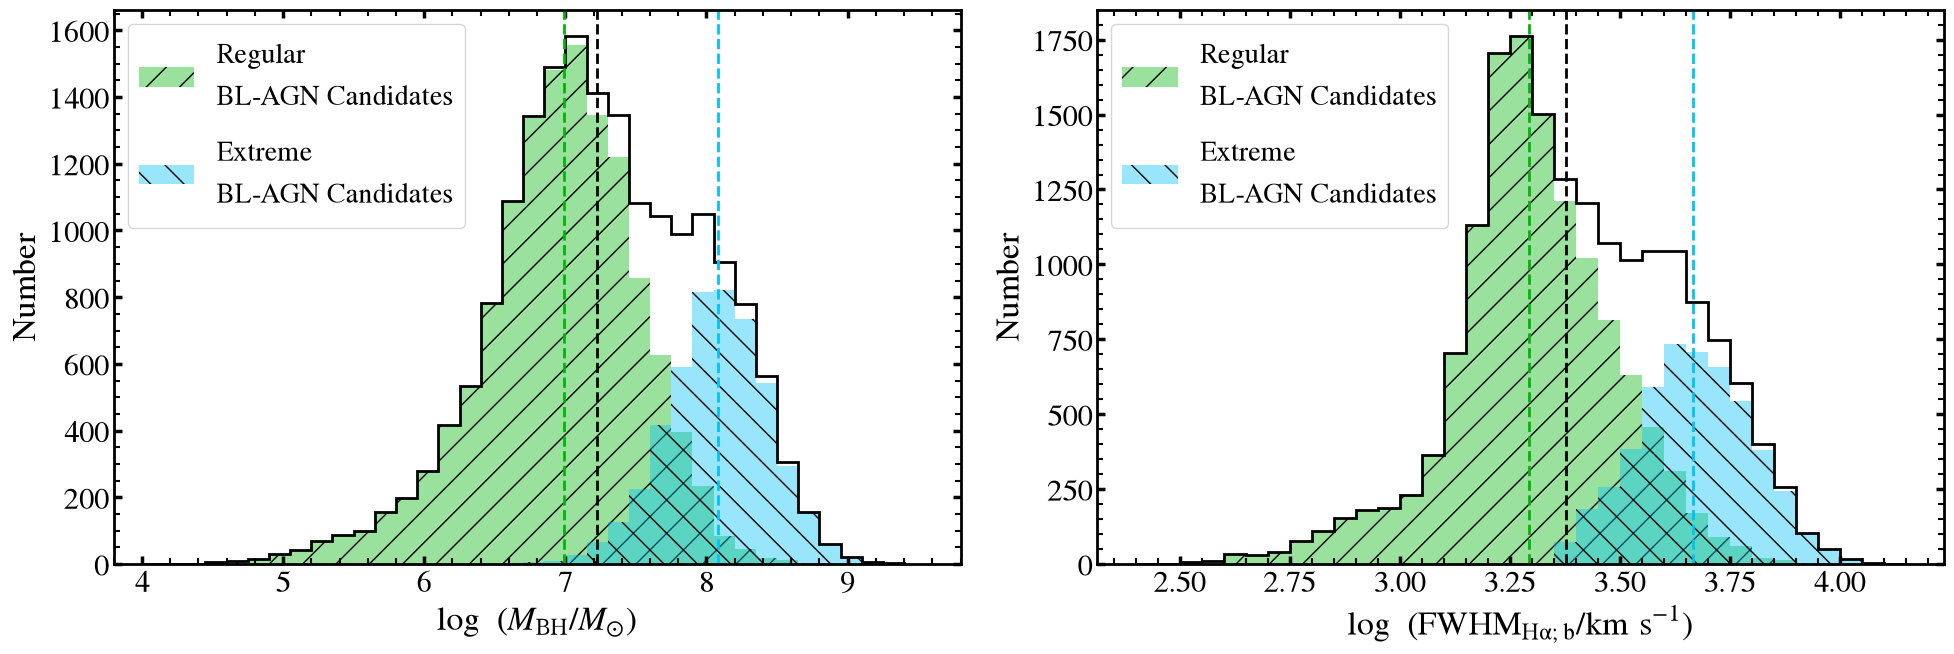

In [15]:
plt.figure(figsize = (20, 7))

plt.subplot2grid((1,2), (0,0))
bh_bins = np.arange(4, 9.5, 0.15)
bh_hist = plt.hist(bh_mass[is_bl&(is_agn|is_comp)&(vi0|vi1)], bins = bh_bins, histtype = 'step', color = 'k', lw = 2.0)
bh_hist1 = plt.hist(bh_mass[is_bl&(is_agn|is_comp)&(vi0|vi1)&is_def], bins = bh_bins, histtype = 'bar', lw = 2.0, alpha = 0.4, color = '#00b408', hatch = '/', label = 'Regular\nBL-AGN Candidates')
bh_hist2 = plt.hist(bh_mass[is_bl&(is_agn|is_comp)&(vi0|vi1)&is_ebl], bins = bh_bins, histtype = 'bar', lw = 2.0, alpha = 0.4, color = '#00c2f9', hatch = '\\', label = 'Extreme\nBL-AGN Candidates')
plt.axvline(np.median(bh_mass[is_bl&(is_agn|is_comp)&(vi0|vi1)]), color = 'k', lw = 2.0, ls = '--')
plt.axvline(np.median(bh_mass[is_bl&(is_agn|is_comp)&(vi0|vi1)&is_def]), color = '#00b408', lw = 2.0, ls = '--')
plt.axvline(np.median(bh_mass[is_bl&(is_agn|is_comp)&(vi0|vi1)&is_ebl]), color = '#00c2f9', lw = 2.0, ls = '--')
plt.xlabel('$\log~(M_{\\rm BH}/M_{\odot})$', fontsize = 24)
plt.ylabel('Number', fontsize = 24)
plt.legend(loc = 'upper left', fontsize = 20)
plt.xlim([3.8, 9.8])

plt.subplot2grid((1,2), (0,1))
ha_bins = np.arange(2.4, 4.2, 0.05)
ha_hist = plt.hist(np.log10(ha_b_fwhm)[is_bl&(is_agn|is_comp)&(vi0|vi1)], bins = ha_bins, histtype = 'step', color = 'k', lw = 2.0)
ha_hist1 = plt.hist(np.log10(ha_b_fwhm)[is_bl&(is_agn|is_comp)&(vi0|vi1)&is_def], bins = ha_bins, histtype = 'bar', lw = 2.0, alpha = 0.4, color = '#00b408', hatch = '/', label = 'Regular \nBL-AGN Candidates')
ha_hist2 = plt.hist(np.log10(ha_b_fwhm)[is_bl&(is_agn|is_comp)&(vi0|vi1)&is_ebl], bins = ha_bins, histtype = 'bar', lw = 2.0, alpha = 0.4, color = '#00c2f9', hatch = '\\', label = 'Extreme \nBL-AGN Candidates')
plt.axvline(np.median(np.log10(ha_b_fwhm)[is_bl&(is_agn|is_comp)&(vi0|vi1)]), color = 'k', lw = 2.0, ls = '--')
plt.axvline(np.median(np.log10(ha_b_fwhm)[is_bl&(is_agn|is_comp)&(vi0|vi1)&is_def]), color = '#00b408', lw = 2.0, ls = '--')
plt.axvline(np.median(np.log10(ha_b_fwhm)[is_bl&(is_agn|is_comp)&(vi0|vi1)&is_ebl]), color = '#00c2f9', lw = 2.0, ls = '--')
plt.xlabel('$\log~(\\rm FWHM_{H\\alpha;b}/km~s^{-1})$', fontsize = 24)
plt.legend(loc = 'upper left', fontsize = 20)
plt.ylabel('Number', fontsize = 24)

plt.tight_layout()

# plt.savefig('bhmass_dist.png')

---